#**LANGKAH PRAKTIKUM**

Langkah 1 — Menyiapkan data & scaling (wajib).

In [8]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Membuat dataset segmentasi pelanggan buatan
np.random.seed(42)
n_samples = 200

data = {
    'usia': np.random.randint(18, 70, size=n_samples),
    'pendapatan': np.random.randint(15, 120, size=n_samples) * 1000, # dalam ribuan
    'skor_belanja': np.random.randint(1, 100, size=n_samples)
}

df = pd.DataFrame(data)
print("5 data pertama:")
display(df.head())
X_scaled = StandardScaler().fit_transform(df)


5 data pertama:


,usia,pendapatan,skor_belanja
0,56,84000,18
1,69,86000,25
2,46,41000,95
3,32,23000,54
4,60,76000,58


Langkah 2 — Metode Elbow menentukan K.

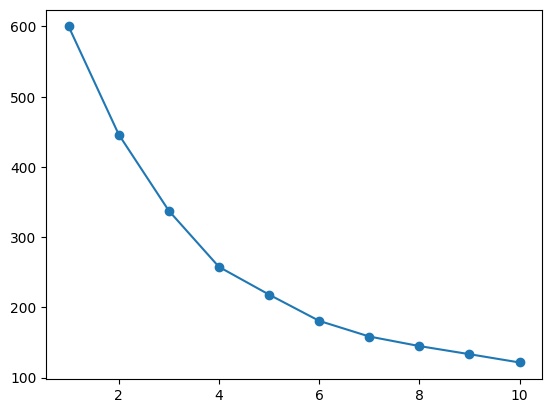

In [9]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


Langkah 3 — Menjalankan K-Means (K=3).

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())



cluster
0    73
1    64
2    63
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [11]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))



0.2659482172373883


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.


In [12]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil



         usia  pendapatan  skor_belanja
cluster                                
0        29.9     75095.9          34.8
1        47.1     77046.9          82.2
2        55.3     47873.0          32.2


**Latihan Mandiri**


Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [ ]:
# Jalankan K-Means dengan K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_5 = kmeans_5.fit_predict(X_scaled)

# Hitung silhouette score untuk K=5
score_k5 = silhouette_score(X_scaled, cluster_5)

# Silhouette score untuk K=3 yang sudah dihitung sebelumnya
score_k3 = silhouette_score(X_scaled, df['cluster'])

# Tampilkan hasil perbandingan
print(f"Silhouette Score untuk K=3: {score_k3:.4f}")
print(f"Silhouette Score untuk K=5: {score_k5:.4f}")

if score_k3 > score_k5:
    print("\nKesimpulan: K=3 memiliki struktur klasterisasi yang lebih baik (silhouette score lebih tinggi).")
else:
    print("\nKesimpulan: K=5 memiliki struktur klasterisasi yang lebih baik (silhouette score lebih tinggi).")

Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya


In [14]:
X_unscaled = df[['usia', 'pendapatan', 'skor_belanja']]

# Menjalankan K-Means (K=3) pada data tanpa scaling
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_unscaled = kmeans_unscaled.fit_predict(X_unscaled)

# Menghitung silhouette score untuk data tanpa scaling
score_unscaled = silhouette_score(X_unscaled, cluster_unscaled)

# Silhouette score untuk data ter-scaling yang dihitung di awal
score_scaled = silhouette_score(X_scaled, df['cluster'])

print(f"Silhouette Score TANPA Scaling (K=3): {score_unscaled:.4f}")
print(f"Silhouette Score DENGAN Scaling (K=3): {score_scaled:.4f}")



Silhouette Score TANPA Scaling (K=3): 0.6215
Silhouette Score DENGAN Scaling (K=3): 0.2659


kesimpulan: Meskipun nilai Silhouette Score tanpa scaling terlihat lebih tinggi (~0.6215 vs ~0.2659), hal ini merupakan bias semu karena algoritma hanya mengelompokkan data berdasarkan fitur pendapatan yang memiliki rentang nilai puluhan ribu, sementara fitur usia dan skor_belanja terabaikan. Oleh karena itu, proses standarisasi (scaling) menggunakan StandardScaler sangat wajib dilakukan agar semua fitur berada pada skala yang setara sehingga algoritma K-Means dapat mendeteksi pola klasterisasi pelanggan secara objektif dan akurat berdasarkan kontribusi seimbang dari ketiga fitur tersebut.

scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

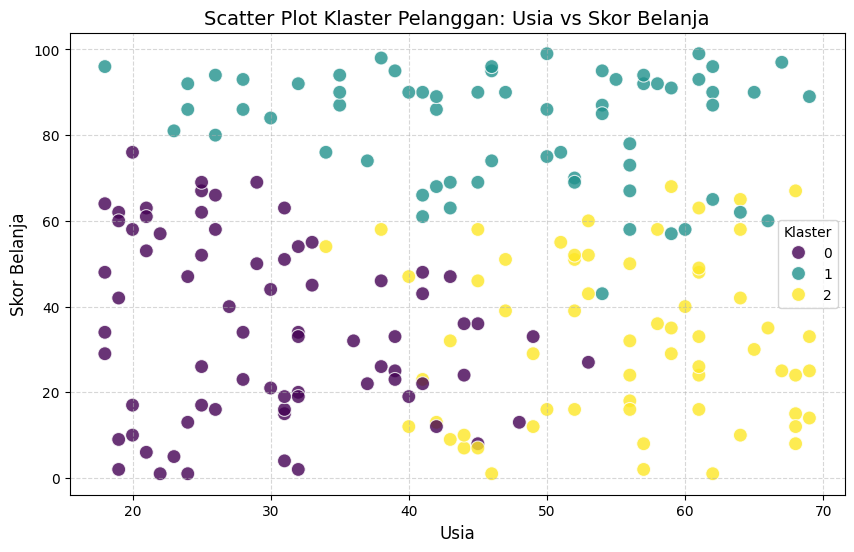

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat scatter plot ulang
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='usia',
    y='skor_belanja',
    hue='cluster',
    palette='viridis',
    data=df,
    s=100,
    alpha=0.8
)

plt.title('Scatter Plot Klaster Pelanggan: Usia vs Skor Belanja', fontsize=14)
plt.xlabel('Usia', fontsize=12)
plt.ylabel('Skor Belanja', fontsize=12)
plt.legend(title='Klaster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Refleksi**

1. **Bagaimana K-Means menemukan kelompok tanpa label?**

   K-Means menemukan kelompok secara mandiri melalui proses pengulangan (iteratif) yang dimulai dengan menentukan beberapa titik pusat klaster awal yang disebut centroid secara acak. Setelah itu, algoritma mengukur jarak antara setiap titik data dengan seluruh centroid tersebut dan memasukkan setiap data ke dalam kelompok yang memiliki centroid terdekat. Posisi centroid kemudian diperbarui dengan menghitung rata-rata dari posisi seluruh data yang masuk ke dalam kelompok tersebut. Proses pemetaan data dan pembaruan centroid ini terus diulang secara konsisten hingga posisi centroid stabil dan tidak mengalami perubahan lagi.

2. **Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**

   Metode Elbow bekerja dengan mengukur inersia atau total kuadrat jarak antara data dengan centroid masing-masing kelompok. Seiring bertambahnya jumlah klaster, nilai inersia ini pasti akan terus menurun mendekati nol. Pada data ini, penurunan inersia yang sangat tajam dan signifikan terjadi dari satu klaster hingga mencapai tiga klaster. Setelah melewati titik tiga klaster, penurunan inersia yang terjadi berikutnya menjadi sangat landai dan tidak terlalu berarti lagi. Perubahan sudut yang mendadak dari penurunan tajam menjadi landai di angka tiga inilah yang membentuk pola menyerupai siku, menandakan bahwa pembentukan tiga klaster adalah pilihan yang paling optimal.

3. **Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**

   Skalabilitas fitur sangat penting karena algoritma K-Means sangat sensitif terhadap perhitungan jarak geometris. Jika proses scaling dilewatkan, fitur pendapatan yang memiliki rentang nilai puluhan ribu akan mendominasi perhitungan jarak sepenuhnya dibandingkan fitur usia dan skor belanja yang rentang nilainya jauh lebih kecil. Dampaknya, algoritma K-Means hanya akan mengelompokkan pelanggan berdasarkan kesamaan pendapatan saja dan mengabaikan karakteristik lainnya. Hal ini menghasilkan bias klasifikasi yang tidak akurat secara objektif meskipun secara metrik nilai kecocokan data tanpa scaling tampak lebih tinggi secara semu.